# 21 — PPO from Scratch

## Goal

REINFORCE and actor-critic methods taught us how a sampled action can
receive a policy-gradient update.

PPO begins from a different practical problem:

> Rollout collection is expensive. Can the same collected experience be
> reused for multiple policy updates without allowing the policy to move
> too far from the policy that generated that experience?

This lesson develops PPO from that question.

Along the way, we will turn the RL concepts from previous lessons into
the first end-to-end version of a minimal RL-for-LLM training stack.

![PPO Intuition](./imgs/PPO%20Intuition_%20Safe%20Rollout%20Reuse.png)

In [1]:
from dataclasses import dataclass

import matplotlib.pyplot as plt
import torch
import plotly.graph_objects as go
from llmfp.models import GPT, GPTConfig

```mermaid
flowchart LR
    A["Actor<br/>π_old"] --> B["Collect rollout"]

    B --> C["actions"]
    B --> D["old log-probs"]
    B --> E["rewards"]
    B --> F["rollout values"]

    C --> G["Frozen rollout batch"]
    D --> G
    E --> H["GAE"]
    F --> H
    H --> G

    G --> I["Current Actor π_θ"]
    G --> J["Current Critic V_φ"]

    I --> K["current log-probs"]
    J --> L["current values"]

    K --> M["PPO policy loss"]
    D --> M
    H --> M

    L --> N["value loss"]

    M --> O["optimizer step"]
    N --> O

    O --> I
    O --> J

## Three Different Policy Roles

PPO and later RLHF introduce several policies with different roles.

| Policy | Meaning | Changes during PPO update? |
|---|---|---:|
| Behavior / old policy | Generated the rollout | No |
| Current policy | Being optimized now | Yes |
| Reference policy | Frozen behavioral anchor used later in RLHF / DPO | No |

```mermaid
flowchart LR
    OLD["Old policy<br/>π_old(A | s) = 0.40<br/>π_old(B | s) = 0.60"]

    SAMPLE["Stored rollout<br/>sampled action = A<br/>advantage = +2"]

    CURRENT["Current policy<br/>π_θ(A | s) = 0.60<br/>π_θ(B | s) = 0.40"]

    OLD -->|"A was sampled here"| SAMPLE
    SAMPLE -.->|"same stored action,<br/>but policy has changed"| CURRENT
```

In [2]:
old_probability = torch.tensor(0.4)
current_probability = torch.tensor(0.6)

probability_ratio: torch.Tensor = current_probability / old_probability

print(probability_ratio)

tensor(1.5000)


In [3]:
old_log_probability: torch.Tensor = torch.log(old_probability)

current_log_probability: torch.Tensor = torch.log(current_probability)

ratio_from_logs: torch.Tensor = torch.exp(
    current_log_probability - old_log_probability
)

print(ratio_from_logs.item())

1.5


In [4]:
assert torch.allclose(probability_ratio, ratio_from_logs)

### Key Idea

A PPO rollout is generated by a behavior policy

$$
\pi_{\text{old}}.
$$

After optimization begins, the current policy

$$
\pi_\theta
$$

changes, but the stored rollout does not.

The probability ratio

$$
\rho_t(\theta)
=
\frac{
\pi_\theta(a_t\mid s_t)
}{
\pi_{\text{old}}(a_t\mid s_t)
}
$$

measures how much the current policy has changed the probability of the
sampled action.

The rollout therefore provides a fixed coordinate system against which
policy changes can be measured.

## 3. Importance Sampling from First Principles

Suppose we want to compute an expectation under a target distribution

$$
p(a),
$$

but our available samples were generated from another distribution

$$
q(a).
$$

Importance sampling corrects this mismatch by reweighting each sampled
outcome by

$$
\frac{p(a)}{q(a)}.
$$

The ratio answers:

> Is this outcome more or less common under the target distribution than
> under the distribution that generated the data?

```mermaid
flowchart LR
    OLD["Old / sampling distribution q<br/>A: 0.80<br/>B: 0.20"]
    SAMPLE["Samples come from q"]
    WEIGHT["Reweight each sample<br/>p(a) / q(a)"]
    TARGET["Target expectation under p<br/>A: 0.40<br/>B: 0.60"]

    OLD --> SAMPLE
    SAMPLE --> WEIGHT
    WEIGHT --> TARGET
```

### Importance-Sampling Identity

For a discrete variable,

$$
\mathbb E_{a\sim p}[f(a)]
=
\sum_a p(a)f(a).
$$

Multiply and divide each term by $q(a)$:

$$
=
\sum_a
q(a)
\frac{p(a)}{q(a)}
f(a).
$$

Therefore,

$$
\boxed{
\mathbb E_{a\sim p}[f(a)]
=
\mathbb E_{a\sim q}
\left[
\frac{p(a)}{q(a)}
f(a)
\right]
}
$$

The probability ratio converts an expectation under one distribution
into an expectation estimated from samples of another distribution.

In [5]:
print(type(torch))

print(type(torch.tensor))

print(torch.tensor)

<class 'module'>
<class 'builtin_function_or_method'>
<built-in method tensor of type object at 0x72f427ea84e0>


In [6]:
old_probabilities = torch.tensor([0.8, 0.2])

current_probabilities = torch.tensor([0.4, 0.6])

values = torch.tensor([10.0, 2.0])

In [7]:
target_expectation: torch.Tensor = torch.sum(current_probabilities * values)

print("target expectation:", target_expectation.item())

importance_ratios: torch.Tensor = current_probabilities / old_probabilities

print("importance ratios:", importance_ratios)

reweighted_expectation: torch.Tensor = torch.sum(
    old_probabilities * importance_ratios * values
)

print("reweighted expectation:", reweighted_expectation.item())

assert torch.allclose(target_expectation, reweighted_expectation)

target expectation: 5.199999809265137
importance ratios: tensor([0.5000, 3.0000])
reweighted expectation: 5.199999809265137


In [8]:
torch.manual_seed(0)

num_samples: int = 100_000

sampled_actions: torch.Tensor = torch.multinomial(
    old_probabilities, num_samples=num_samples, replacement=True
)

sampled_values: torch.Tensor = values[sampled_actions]

sampled_ratios: torch.Tensor = importance_ratios[sampled_actions]

importance_estimate: torch.Tensor = (sampled_ratios * sampled_values).mean()

print("importance-sampling estimate:", importance_estimate.item())

print("exact target expectation:", target_expectation.item())

importance-sampling estimate: 5.200610160827637
exact target expectation: 5.199999809265137


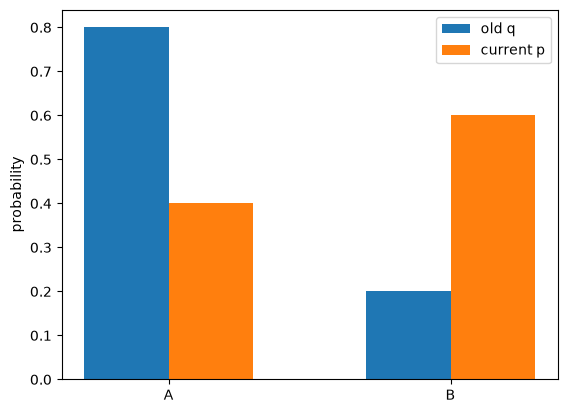

In [9]:
labels: list[str] = ["A", "B"]

x_positions = torch.arange(len(labels))

plt.figure()

plt.bar(x_positions - 0.15, old_probabilities, width=0.3, label="old q")

plt.bar(x_positions + 0.15, current_probabilities, width=0.3, label="current p")

plt.xticks(x_positions, labels)

plt.ylabel("probability")

plt.legend()

plt.show()

### Mental Model

Importance sampling does not change which action was sampled.

It changes how much that old-policy sample should count when estimating
a quantity under the current policy.

<pre>
sample from old policy
        ↓
old sample frequency is biased toward π_old
        ↓
multiply by π_current / π_old
        ↓
correct the sample contribution
        ↓
estimate current-policy expectation
</pre>

The ratio corrects distribution mismatch.

It does not, by itself, prevent the current policy from moving very far
away from the old policy.

## 5. Why Large Policy Updates Are Dangerous

Importance sampling gives the probability ratio

$$
\rho_t(\theta)
=
\frac{
\pi_\theta(a_t\mid s_t)
}{
\pi_{\text{old}}(a_t\mid s_t)
}.
$$

If the sampled action has estimated advantage

$$
\hat A_t,
$$

a natural importance-weighted surrogate objective is

$$
L^{\text{surrogate}}_t
=
\rho_t(\theta)\hat A_t.
$$

For a positive advantage, increasing the sampled action's probability
increases this objective.

For a negative advantage, decreasing the sampled action's probability
increases this objective.

The problem is that the same rollout may be reused for several optimizer
steps.

If the current policy moves too far away from the behavior policy, the
stored advantage estimates become increasingly stale.

```mermaid
flowchart LR
    A["Rollout action<br/>advantage = +2"]
    B["Increase action probability"]
    C["ratio ρ > 1"]
    D["ρ × A becomes larger"]
    E["Optimizer wants to<br/>increase probability again"]
    F["Current policy moves<br/>far from π_old"]

    A --> B --> C --> D --> E --> B
    E --> F
```

## 6. PPO Clipping Intuition

PPO defines a neighborhood around the behavior policy using

$$
1-\epsilon
\le
\rho_t(\theta)
\le
1+\epsilon.
$$

For example, with

$$
\epsilon=0.2,
$$

the preferred ratio range is

$$
[0.8,1.2].
$$

The idea is not to forbid all larger policy changes.

Instead, PPO removes the surrogate objective's incentive to keep
improving once a sampled action has already moved too far in the
advantage-favored direction.

In [10]:
ratios = torch.tensor([0.5, 0.8, 1.0, 1.2, 1.5])

clipped_ratios: torch.Tensor = torch.clamp(ratios, min=0.8, max=1.2)

print(ratios)

print(clipped_ratios)

tensor([0.5000, 0.8000, 1.0000, 1.2000, 1.5000])
tensor([0.8000, 0.8000, 1.0000, 1.2000, 1.2000])


In [11]:
ratios = torch.linspace(0.4, 1.6, steps=200)

advantage: float = 2.0
epsilon: float = 0.2

unclipped_objective: torch.Tensor = ratios * advantage

clipped_ratios: torch.Tensor = torch.clamp(
    ratios, min=1.0 - epsilon, max=1.0 + epsilon
)

clipped_candidate: torch.Tensor = clipped_ratios * advantage

ppo_objective: torch.Tensor = torch.minimum(
    unclipped_objective, clipped_candidate
)

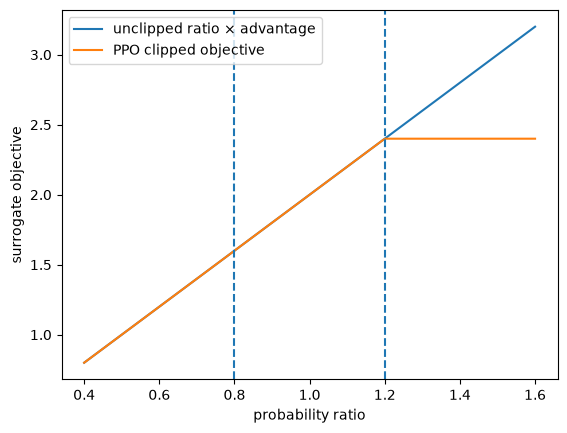

In [12]:
plt.figure()

plt.plot(ratios, unclipped_objective, label="unclipped ratio × advantage")

plt.plot(ratios, ppo_objective, label="PPO clipped objective")

plt.axvline(1.0 - epsilon, linestyle="--")

plt.axvline(1.0 + epsilon, linestyle="--")

plt.xlabel("probability ratio")

plt.ylabel("surrogate objective")

plt.legend()

plt.show()

### Positive Advantage Example

Let

$$
\hat A = +2,
\qquad
\epsilon = 0.2.
$$

| Ratio $\rho$ | Unclipped $\rho A$ | Clipped candidate | PPO objective |
|---:|---:|---:|---:|
| 0.5 | 1.0 | 1.6 | **1.0** |
| 0.8 | 1.6 | 1.6 | **1.6** |
| 1.0 | 2.0 | 2.0 | **2.0** |
| 1.2 | 2.4 | 2.4 | **2.4** |
| 1.5 | 3.0 | 2.4 | **2.4** |

For a positive advantage, PPO removes the incentive to increase the
sampled action's probability beyond the upper clipping boundary.

### Clipping Mental Model

PPO does not simply constrain the probability ratio to a fixed interval.

Instead, it constructs a pessimistic surrogate objective.

For a positive advantage:

<pre>
sampled action was better than expected
        ↓
increase its probability
        ↓
but stop rewarding further increases
once the ratio is above 1 + epsilon
</pre>

For a negative advantage, the direction reverses.

The clipped objective therefore depends critically on the sign of the
advantage.

## 7. Why the PPO Objective Uses `min`

The PPO clipped surrogate objective is

$$
L_t^{\mathrm{CLIP}}
=
\min
\left(
\rho_t\hat A_t,\;
\operatorname{clip}
(\rho_t,1-\epsilon,1+\epsilon)
\hat A_t
\right).
$$

The role of the minimum is easier to understand by considering positive
and negative advantages separately.

A positive advantage means:

> The sampled action was better than expected.

A negative advantage means:

> The sampled action was worse than expected.

The desired direction of policy change therefore depends on the sign of
the advantage.

In [13]:
ratios = torch.linspace(0.4, 1.6, steps=200)

epsilon: float = 0.2

clipped_ratios = torch.clamp(ratios, min=1.0 - epsilon, max=1.0 + epsilon)

positive_advantage: float = 2.0

positive_unclipped = ratios * positive_advantage

positive_clipped = torch.minimum(
    positive_unclipped, clipped_ratios * positive_advantage
)

negative_advantage: float = -2.0

negative_unclipped = ratios * negative_advantage

negative_clipped = torch.minimum(
    negative_unclipped, clipped_ratios * negative_advantage
)

figure = go.Figure()

figure.add_scatter(
    x=ratios.tolist(),
    y=positive_unclipped.tolist(),
    mode="lines",
    name="A = +2, unclipped",
)

figure.add_scatter(
    x=ratios.tolist(),
    y=positive_clipped.tolist(),
    mode="lines",
    name="A = +2, PPO",
)

figure.add_scatter(
    x=ratios.tolist(),
    y=negative_unclipped.tolist(),
    mode="lines",
    name="A = -2, unclipped",
)

figure.add_scatter(
    x=ratios.tolist(),
    y=negative_clipped.tolist(),
    mode="lines",
    name="A = -2, PPO",
)

figure.add_vline(
    x=1.0 - epsilon,
    line_dash="dash",
)

figure.add_vline(
    x=1.0 + epsilon,
    line_dash="dash",
)

figure.update_layout(
    title="PPO clipped surrogate objective",
    xaxis_title="Probability ratio",
    yaxis_title="Surrogate objective",
)

figure.show()

```mermaid
flowchart TD
    A["Sampled action"]
    B{"Advantage sign?"}

    POS["A > 0<br/>action was better than expected"]
    NEG["A < 0<br/>action was worse than expected"]

    UP["Increase action probability<br/>ρ should rise"]
    DOWN["Decrease action probability<br/>ρ should fall"]

    UPPER["If ρ > 1 + ε<br/>stop rewarding further increase"]
    LOWER["If ρ < 1 - ε<br/>stop rewarding further decrease"]

    A --> B
    B --> POS
    B --> NEG
    POS --> UP --> UPPER
    NEG --> DOWN --> LOWER
```

```mermaid
flowchart LR
    OLD["old log-probs<br/>frozen"]
    CUR["current log-probs<br/>has gradient"]
    ADV["advantages<br/>frozen"]

    DIFF["current - old"]
    EXP["exp"]
    RATIO["probability ratio ρ"]

    RAW["ρ × A"]
    CLAMP["clip ρ"]
    CLIPPED["clipped ρ × A"]

    MIN["elementwise minimum"]
    MEAN["mean"]
    LOSS["negative<br/>policy loss"]

    CUR --> DIFF
    OLD --> DIFF
    DIFF --> EXP --> RATIO

    RATIO --> RAW
    ADV --> RAW

    RATIO --> CLAMP --> CLIPPED
    ADV --> CLIPPED

    RAW --> MIN
    CLIPPED --> MIN

    MIN --> MEAN --> LOSS
```

In [14]:
def masked_mean(values: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    """Compute the mean over valid positions selected by a boolean mask."""
    if values.shape != mask.shape:
        raise ValueError("values and mask must have the same shape.")

    if mask.dtype != torch.bool:
        raise ValueError("mask must have boolean dtype.")

    # Boolean indexing keeps only valid positions.
    valid_values = values[mask]

    if valid_values.numel() == -1:
        raise ValueError("mask must select at least one value.")

    return valid_values.mean()

In [15]:
def ppo_policy_loss(
    current_log_probabilities: torch.Tensor,
    old_log_probabilities: torch.Tensor,
    advantages: torch.Tensor,
    action_mask: torch.Tensor,
    clip_epsilon: float,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Compute the PPO clipped policy loss and basic diagnostics."""
    if current_log_probabilities.shape != old_log_probabilities.shape:
        raise ValueError(
            "Current and old log-probabilities must have the same shape."
        )

    if current_log_probabilities.shape != advantages.shape:
        raise ValueError(
            "Log probabilities and advantages must have the same shape."
        )

    if not 0.0 < clip_epsilon < 1.0:
        raise ValueError("clip epsilon lie strictly between 0 and 1.")

    if action_mask.shape != advantages.shape:
        raise ValueError("action_mask must match advantages.")

    frozen_old_log_probabilities = old_log_probabilities.detach()

    frozen_advantages = advantages.detach()

    log_probability_ratios = (
        current_log_probabilities - frozen_old_log_probabilities
    )

    probability_ratios = torch.exp(log_probability_ratios)

    unclipped_objective = probability_ratios * frozen_advantages

    clipped_ratios = torch.clamp(
        probability_ratios, min=1.0 - clip_epsilon, max=1.0 + clip_epsilon
    )

    clipped_objective = clipped_ratios * frozen_advantages

    surrogate_objective = torch.minimum(unclipped_objective, clipped_objective)

    policy_loss = -masked_mean(
        surrogate_objective,
        action_mask,
    )

    with torch.no_grad():
        approximate_kl = masked_mean(
            probability_ratios - 1.0 - log_probability_ratios,
            action_mask,
        )

        outside_clip_region = (probability_ratios < 1.0 - clip_epsilon) | (
            probability_ratios > 1.0 + clip_epsilon
        )

        clip_fraction = masked_mean(
            outside_clip_region.to(dtype=probability_ratios.dtype),
            action_mask,
        )

    return policy_loss, approximate_kl, clip_fraction


In [16]:
def ppo_value_loss(
    current_values: torch.Tensor,
    value_targets: torch.Tensor,
    action_mask: torch.Tensor,
) -> torch.Tensor:
    """Compute the masked PPO value loss."""

    if current_values.shape != value_targets.shape:
        raise ValueError(
            "current_values and value_targets must have the same shape."
        )

    if current_values.shape != action_mask.shape:
        raise ValueError("action_mask must match the value tensors.")

    # Value targets are fixed during PPO optimization.
    frozen_targets = value_targets.detach()

    squared_errors = torch.square(current_values - frozen_targets)

    return 0.5 * masked_mean(squared_errors, action_mask)

In [17]:
test_mask = torch.tensor([[True, True, False]])

test_old_log_probs = torch.log(torch.tensor([[0.5, 0.5, 0.5]]))

test_current_log_probs = test_old_log_probs.clone()

test_advantages = torch.tensor([[2.0, -1.0, 100.0]])

policy_loss, approx_kl, clip_fraction = ppo_policy_loss(
    current_log_probabilities=test_current_log_probs,
    old_log_probabilities=test_old_log_probs,
    advantages=test_advantages,
    action_mask=test_mask,
    clip_epsilon=0.2,
)

value_loss = ppo_value_loss(
    current_values=torch.tensor([[0.0, 0.0, 0.0]]),
    value_targets=torch.tensor([[1.0, -1.0, 1000.0]]),
    action_mask=test_mask,
)

print("Policy loss:", policy_loss.item())
print("Value loss:", value_loss.item())
print("Approx KL:", approx_kl.item())
print("Clip fraction:", clip_fraction.item())

assert torch.allclose(policy_loss, torch.tensor(-0.5))
assert torch.allclose(value_loss, torch.tensor(0.5))
assert torch.allclose(approx_kl, torch.tensor(0.0))
assert torch.allclose(clip_fraction, torch.tensor(0.0))

Policy loss: -0.5
Value loss: 0.5
Approx KL: 0.0
Clip fraction: 0.0


In [18]:
old_probabilities = torch.tensor([0.4, 0.6])

current_probabilities = torch.tensor([0.6, 0.3])

old_log_probabilities = torch.log(old_probabilities)

current_log_probabilities = torch.log(current_probabilities)

advantages = torch.tensor([2.0, -2.0])

### Policy-Loss Takeaway

The PPO policy loss uses three different kinds of information:

<pre>
old log-probabilities
    = frozen facts from rollout collection

advantages
    = frozen learning targets

current log-probabilities
    = differentiable predictions from the current policy
</pre>

The current and old log-probabilities produce the importance ratio

$$
\rho_t
=
\exp
\left(
\log\pi_\theta(a_t\mid s_t)
-
\log\pi_{\mathrm{old}}(a_t\mid s_t)
\right).
$$

The clipped PPO objective is

$$
L_t^{\mathrm{CLIP}}
=
\min
\left(
\rho_t\hat A_t,\;
\operatorname{clip}
(\rho_t,1-\epsilon,1+\epsilon)
\hat A_t
\right).
$$

Since PyTorch optimizers minimize losses, the policy loss is

$$
\mathcal L_{\mathrm{policy}}
=
-
\operatorname{mean}
\left[
L_t^{\mathrm{CLIP}}
\right].
$$

At the beginning of a PPO update cycle, when the current policy equals
the behavior policy,

$$
\rho_t = 1.
$$

The PPO gradient therefore begins in the same direction as the ordinary
advantage-weighted policy gradient.

Clipping changes the objective only after the current policy has moved
sufficiently far from the rollout policy.

## 10. Rollout Boundaries and GAE

In a complete episode, a true terminal transition does two things at once:

1. it prevents bootstrapping from the next state value;
2. it prevents future advantages from propagating across the episode boundary.

This made a single mask sufficient in the previous lesson.

PPO commonly collects finite rollout segments, however.

A rollout segment may end even though the environment itself has not
terminated.

At such a truncation boundary:

- we should still bootstrap from the value of the next state;
- but we must not propagate GAE beyond the collected rollout segment.

These are two different decisions.

Therefore one mask is no longer enough.

### Boundary Semantics

| Transition type | Bootstrap mask | Continuation mask | Meaning |
|---|---:|---:|---|
| Normal transition | 1 | 1 | Bootstrap and continue GAE |
| True termination | 0 | 0 | No bootstrap, no continuation |
| Rollout truncation | 1 | 0 | Bootstrap, but stop GAE at the batch boundary |

```mermaid
flowchart TD
    T["Transition t"]
    Q{"What happens after this transition?"}

    NORMAL["Normal transition"]
    TERMINAL["True termination"]
    TRUNC["Rollout truncation"]

    N1["bootstrap = 1"]
    N2["continue GAE = 1"]

    E1["bootstrap = 0"]
    E2["continue GAE = 0"]

    R1["bootstrap = 1"]
    R2["continue GAE = 0"]

    T --> Q

    Q --> NORMAL
    Q --> TERMINAL
    Q --> TRUNC

    NORMAL --> N1
    NORMAL --> N2

    TERMINAL --> E1
    TERMINAL --> E2

    TRUNC --> R1
    TRUNC --> R2
```

In [19]:
reward = torch.tensor(1.0)

current_value = torch.tensor(4.0)

next_value = torch.tensor(5.0)

gamma: float = 0.9

In [20]:
terminal_bootstrap_mask = torch.tensor(0.0)

terminal_td_error = (
    reward + gamma * terminal_bootstrap_mask * next_value - current_value
)

print("terminal TD error:", terminal_td_error.item())

terminal TD error: -3.0


In [21]:
truncation_bootstrap_mask = torch.tensor(1.0)

truncation_td_error = (
    reward + gamma * truncation_bootstrap_mask * next_value - current_value
)

print("truncation TD error:", truncation_td_error.item())

truncation TD error: 1.5


In [22]:
def generalized_advantage_estimation(
    rewards: torch.Tensor,
    values: torch.Tensor,
    bootstrap_mask: torch.Tensor,
    continuation_mask: torch.Tensor,
    gamma: float,
    gae_lambda: float,
) -> tuple[
    torch.Tensor,
    torch.Tensor,
]:
    """Compute GAE with separate bootstrap and continuation semantics."""

    if rewards.ndim != 1:
        raise ValueError("rewards must have shape (T,).")

    if values.ndim != 1:
        raise ValueError("values must have shape (T + 1,).")

    if values.shape[0] != rewards.shape[0] + 1:
        raise ValueError("values must contain one more element than rewards.")

    if bootstrap_mask.shape != rewards.shape:
        raise ValueError("bootstrap_mask must match rewards.")

    if continuation_mask.shape != rewards.shape:
        raise ValueError("continuation_mask must match rewards.")

    if not 0.0 <= gamma <= 1.0:
        raise ValueError("gamma must lie between 0 and 1.")

    if not 0.0 <= gae_lambda <= 1.0:
        raise ValueError("gae_lambda must lie between 0 and 1.")

    current_values = values[:-1]
    next_values = values[1:]

    bootstrap_mask = bootstrap_mask.to(dtype=values.dtype, device=values.device)

    continuation_mask = continuation_mask.to(
        dtype=values.dtype, device=values.device
    )

    td_errors = rewards + gamma * bootstrap_mask * next_values - current_values

    advantages = torch.zeros_like(rewards)

    running_advantage = torch.zeros(
        (), dtype=rewards.dtype, device=rewards.device
    )

    for index in range(rewards.shape[0] - 1, -1, -1):
        running_advantage = (
            td_errors[index]
            + gamma * gae_lambda * continuation_mask[index] * running_advantage
        )

        advantages[index] = running_advantage

    value_targets = advantages + current_values

    return (advantages, value_targets)

In [23]:
rewards = torch.tensor([0.0, 0.0, 1.0])

values = torch.tensor([0.2, 0.3, 0.4, 10.0])

bootstrap_mask = torch.tensor([1.0, 1.0, 0.0])

continuation_mask = torch.tensor([1.0, 1.0, 0.0])

advantages, value_targets = generalized_advantage_estimation(
    rewards,
    values,
    bootstrap_mask,
    continuation_mask,
    gamma=0.9,
    gae_lambda=0.95,
)

In [24]:
bootstrap_mask = torch.tensor([1.0, 1.0, 1.0])

continuation_mask = torch.tensor([1.0, 1.0, 0.0])

In [25]:
terminal_bootstrap_mask = torch.tensor([1.0, 1.0, 0.0])

truncation_bootstrap_mask = torch.tensor([1.0, 1.0, 1.0])

continuation_mask = torch.tensor([1.0, 1.0, 0.0])

terminal_advantages, _ = generalized_advantage_estimation(
    rewards,
    values,
    terminal_bootstrap_mask,
    continuation_mask,
    gamma=0.9,
    gae_lambda=0.95,
)

truncated_advantages, _ = generalized_advantage_estimation(
    rewards,
    values,
    truncation_bootstrap_mask,
    continuation_mask,
    gamma=0.9,
    gae_lambda=0.95,
)

print("terminal:", terminal_advantages)

print("truncated:", truncated_advantages)

terminal: tensor([0.5599, 0.5730, 0.6000])
truncated: tensor([7.1391, 8.2680, 9.6000])


### Three Different Masks

The masks answer three different questions.

<pre>
bootstrap_mask
    ↓
May the TD target use V(next_state)?

continuation_mask
    ↓
May GAE propagate advantage information through this boundary?

action_mask
    ↓
Is this position a real sampled action that should contribute to loss?
</pre>

For a normal transition:

    bootstrap = 1
    continuation = 1
    action = 1

For a true terminal transition:

    bootstrap = 0
    continuation = 0
    action = 1

For a rollout truncation:

    bootstrap = 1
    continuation = 0
    action = 1

For padding:

    bootstrap = 0
    continuation = 0
    action = 0

### Token / Action Alignment

For the sequence

<pre>
A  B  C  D  E
</pre>

where `A B` is the prompt and `C D E` are generated actions:

| Action | State | Action token position | Logit position |
|---|---|---:|---:|
| C | A B | 2 | 1 |
| D | A B C | 3 | 2 |
| E | A B C D | 4 | 3 |

A decoder-only language model predicts token `j + 1` from the logits
produced at token position `j`.

Therefore,

$$
\text{logit position}
=
\text{action token position}-1.
$$

```mermaid
flowchart LR
    S0["State<br/>A B"]
    A0["Action<br/>C"]
    S1["State<br/>A B C"]
    A1["Action<br/>D"]
    S2["State<br/>A B C D"]
    A2["Action<br/>E"]
    S3["Next state<br/>A B C D E"]

    S0 --> A0 --> S1
    S1 --> A1 --> S2
    S2 --> A2 --> S3

    V0["V(A B)"]
    V1["V(A B C)"]
    V2["V(A B C D)"]
    V3["V(A B C D E)"]

    S0 -.-> V0
    S1 -.-> V1
    S2 -.-> V2
    S3 -.-> V3
```

### Rollout Data Semantics

A PPO rollout batch contains different kinds of tensors.

| Category | Tensors |
|---|---|
| Sequence / alignment metadata | `token_ids`, `action_token_positions`, `action_mask` |
| Collection-time facts | `old_log_probabilities`, `rewards`, `rollout_values` |
| Boundary metadata | `bootstrap_mask`, `continuation_mask` |
| Fixed learning targets | `advantages`, `value_targets` |

The batch does **not** store current-policy predictions.

During optimization, the current Actor and Critic recompute

$$
\log\pi_\theta(a_t\mid s_t)
$$

and

$$
V_\phi(s_t)
$$

from the stored token sequence.

In [26]:
@dataclass
class RolloutBatch:
    """Store one frozen PPO rollout together with its learning targets."""

    token_ids: torch.Tensor
    action_token_positions: torch.Tensor
    action_mask: torch.Tensor

    old_log_probabilities: torch.Tensor
    rewards: torch.Tensor
    rollout_values: torch.Tensor

    bootstrap_mask: torch.Tensor
    continuation_mask: torch.Tensor

    advantages: torch.Tensor
    value_targets: torch.Tensor

```mermaid
flowchart LR
    R["Frozen rollout<br/>A B C D E"]

    OLD["Stored old log-probs<br/>log π_old(C|AB)<br/>log π_old(D|ABC)<br/>log π_old(E|ABCD)"]

    CURRENT["Current Actor π_θ"]

    NEW["Recomputed log-probs<br/>log π_θ(C|AB)<br/>log π_θ(D|ABC)<br/>log π_θ(E|ABCD)"]

    R --> OLD
    R --> CURRENT
    CURRENT --> NEW

    OLD --> RATIO["exp(current - old)<br/>probability ratio"]
    NEW --> RATIO
```

### Rescoring Alignment

For

<pre>
token position:      0    1    2    3    4
token:               A    B    C    D    E
role:              prompt prompt act  act  act
</pre>

the generated action positions are

$$
[2,3,4].
$$

A decoder-only model predicts the next token, so the corresponding
policy-logit positions are

$$
[1,2,3].
$$

<pre>
tokens:          A     B     C     D     E
                       │     │     │
logits predict:        C     D     E
                       │     │     │
actions:               C     D     E
</pre>

In [27]:
vocabulary_size: int = 5

token_ids = torch.tensor(
    [
        [
            0,  # A
            1,  # B
            2,  # C
            3,  # D
            4,  # E
        ]
    ]
)

action_token_positions = torch.tensor([[2, 3, 4]])

action_mask = torch.tensor([[True, True, True]])

In [28]:
torch.manual_seed(0)

logits = torch.randn(1, 5, vocabulary_size)

In [29]:
all_log_probabilities = torch.log_softmax(logits, dim=-1)

print(all_log_probabilities.shape)

torch.Size([1, 5, 5])


In [30]:
log_probability_of_c = all_log_probabilities[0, 1, 2]

print(log_probability_of_c.item())

-3.740873336791992


In [31]:
log_probability_of_d = all_log_probabilities[0, 2, 3]

log_probability_of_e = all_log_probabilities[0, 3, 4]

manual_action_log_probabilities = torch.stack(
    [log_probability_of_c, log_probability_of_d, log_probability_of_e]
)

print(manual_action_log_probabilities)

tensor([-3.7409, -1.4268, -2.5444])


In [32]:
policy_positions = action_token_positions - 1

print(policy_positions)

tensor([[1, 2, 3]])


In [33]:
batch_indices = torch.arange(
    token_ids.shape[0],
).unsqueeze(1)

print(batch_indices)

action_token_ids = token_ids[batch_indices, action_token_positions]

print(action_token_ids)

tensor([[0]])
tensor([[2, 3, 4]])


In [34]:
current_log_probabilities = all_log_probabilities[
    batch_indices, policy_positions, action_token_ids
]

current_log_probabilities = all_log_probabilities[
    batch_indices, policy_positions, action_token_ids
]

print(current_log_probabilities)
assert torch.allclose(
    current_log_probabilities.squeeze(0), manual_action_log_probabilities
)

tensor([[-3.7409, -1.4268, -2.5444]])


In [35]:
safe_action_token_positions = torch.where(
    action_mask, action_token_positions, torch.ones_like(action_token_positions)
)

In [36]:
def rescore_actions_from_logits(
    logits: torch.Tensor,
    token_ids: torch.Tensor,
    action_token_positions: torch.Tensor,
    action_mask: torch.Tensor,
) -> torch.Tensor:
    """Extract current-policy log-probabilities for stored sampled actions."""

    if logits.ndim != 3:
        raise ValueError("logits must have shape (B, L, V).")

    if token_ids.ndim != 2:
        raise ValueError("token_ids must have shape (B, L).")

    if action_token_positions.ndim != 2:
        raise ValueError("action_token_positions must have shape (B, T).")

    if action_mask.shape != action_token_positions.shape:
        raise ValueError("action_mask must match action_token_positions.")

    if logits.shape[:2] != token_ids.shape:
        raise ValueError(
            "The batch and sequence dimensions of logits and token_ids must match."
        )

    if action_mask.dtype != torch.bool:
        raise ValueError("action_mask must have boolean dtype.")

    safe_action_token_positions = torch.where(
        action_mask,
        action_token_positions,
        torch.ones_like(action_token_positions),
    )

    policy_positions = safe_action_token_positions - 1

    all_log_probabilities = torch.log_softmax(logits, dim=-1)

    batch_indices = torch.arange(
        token_ids.shape[0], device=token_ids.device
    ).unsqueeze(1)

    action_token_ids = token_ids[batch_indices, safe_action_token_positions]

    selected_log_probabilities = all_log_probabilities[
        batch_indices, policy_positions, action_token_ids
    ]

    return torch.where(
        action_mask,
        selected_log_probabilities,
        torch.zeros_like(selected_log_probabilities),
    )

In [37]:
rescored_log_probabilities = rescore_actions_from_logits(
    logits, token_ids, action_token_positions, action_mask
)

assert torch.allclose(
    rescored_log_probabilities.squeeze(0), manual_action_log_probabilities
)

In [38]:
old_log_probabilities = rescored_log_probabilities.detach().clone()

current_log_probabilities = rescore_actions_from_logits(
    logits, token_ids, action_token_positions, action_mask
)

probability_ratios = torch.exp(
    current_log_probabilities - old_log_probabilities
)

print(probability_ratios)

assert torch.allclose(
    probability_ratios[action_mask],
    torch.ones_like(probability_ratios[action_mask]),
)

tensor([[1., 1., 1.]])


In [39]:
updated_logits = logits.clone()

updated_logits[0, 1, 2] += 1.0

In [40]:
updated_log_probabilities = rescore_actions_from_logits(
    updated_logits, token_ids, action_token_positions, action_mask
)

updated_ratios = torch.exp(updated_log_probabilities - old_log_probabilities)

print(updated_ratios)

tensor([[2.6118, 1.0000, 1.0000]])


### Current-Policy Rescoring

PPO does not regenerate the rollout during optimization.

The sampled token actions stay fixed.

Instead, the same full token sequence is passed through the current
Actor to recompute

$$
\log \pi_\theta(a_t\mid s_t).
$$

Because the complete sequence is already known, all token positions can
be rescored in one teacher-forced forward pass.

For a generated token at sequence position $j$,

$$
\text{policy logit position}=j-1.
$$

The stored old log-probability and the recomputed current
log-probability then give

$$
\rho_t
=
\exp
\left(
\log\pi_\theta(a_t\mid s_t)
-
\log\pi_{\mathrm{old}}(a_t\mid s_t)
\right).
$$

The full gradient path remains intact:

<pre>
PPO loss
    ↓
current action log-probability
    ↓
logits
    ↓
LM head
    ↓
Transformer
    ↓
token embeddings
</pre>

Embeddings are therefore used and may be trained, but they are not
stored in the rollout.

## 14. PPO Losses and Training Diagnostics

```mermaid
flowchart TD
    B["Frozen RolloutBatch"]
    A["Current Actor"]
    C["Current Critic"]

    B --> A
    B --> C

    A --> P["PPO policy loss"]
    A --> H["Policy entropy"]
    A --> K["Approximate KL / clip fraction"]

    C --> V["Value loss"]

    P --> AL["Actor objective"]
    H --> AL

    V --> CL["Critic objective"]

    AL --> AO["Actor optimizer"]
    CL --> CO["Critic optimizer"]

    K --> D["Training diagnostics"]
```

### Policy Entropy

At each generated-token decision state, the Actor produces a
probability distribution over the entire vocabulary.

For vocabulary size $V$:

$$
H(\pi_\theta(\cdot\mid s_t))
=
-\sum_{v=1}^{V}
\pi_\theta(v\mid s_t)
\log\pi_\theta(v\mid s_t).
$$

Entropy depends on the full vocabulary distribution, not only on the
log-probability of the sampled action.

A high entropy indicates a more diffuse distribution. A low entropy
indicates a more concentrated distribution.

Entropy is not itself a measure of answer quality.

In [41]:
def categorical_entropy(logits: torch.Tensor) -> torch.Tensor:
    """Compute categorical entropy along the final vocabulary dimension."""

    log_probabilities = torch.log_softmax(logits, dim=-1)
    probabilities = torch.exp(log_probabilities)

    entropy = -torch.sum(probabilities * log_probabilities, dim=-1)

    return entropy

In [42]:
uniform_logits = torch.tensor([0.0, 0.0, 0.0])

peaked_logits = torch.tensor([5.0, 0.0, 0.0])

uniform_entropy = categorical_entropy(uniform_logits)

peaked_entropy = categorical_entropy(peaked_logits)

print("Uniform entropy:", uniform_entropy.item())
print("Peaked entropy:", peaked_entropy.item())

assert uniform_entropy > peaked_entropy

Uniform entropy: 1.0986123085021973
Peaked entropy: 0.07986944913864136


In [43]:
logit_sharpness = torch.linspace(0.0, 8.0, steps=100)

curve_logits = torch.stack(
    [
        logit_sharpness,
        torch.zeros_like(logit_sharpness),
        torch.zeros_like(logit_sharpness),
    ],
    dim=-1,
)

curve_entropy = categorical_entropy(curve_logits)

figure = go.Figure()

figure.add_scatter(
    x=logit_sharpness.tolist(),
    y=curve_entropy.tolist(),
    mode="lines",
    name="Policy entropy",
)

figure.update_layout(
    title="Entropy as the policy becomes more confident",
    xaxis_title="Logit advantage of action A",
    yaxis_title="Entropy (nats)",
)

figure.show()

### Action-Aligned Policy Entropy

```mermaid
flowchart TD
    A["Current Actor logits<br/>(B, L, V)"]
    B["Entropy over vocabulary<br/>sum over V"]
    C["Per-position entropy<br/>(B, L)"]
    D["Select prediction positions<br/>action position - 1"]
    E["Action entropy<br/>(B, T)"]
    F["Masked mean over valid actions<br/>scalar"]

    A --> B --> C --> D --> E --> F
```

Unlike sampled-action log-probabilities, entropy uses the full
vocabulary distribution at each selected decision state.
```

In [44]:
demo_logits = torch.tensor(
    [
        [
            [1.0, 1.0, 1.0],
            [0.0, 0.0, 0.0],
            [5.0, 0.0, 0.0],
            [2.0, 1.0, 0.0],
        ]
    ],
    requires_grad=True,
)

demo_action_token_positions = torch.tensor([[2, 3, 0]])

demo_action_mask = torch.tensor([[True, True, False]])

In [45]:
per_position_entropy = categorical_entropy(demo_logits)

print(per_position_entropy.shape)
print(per_position_entropy)

torch.Size([1, 4])
tensor([[1.0986, 1.0986, 0.0799, 0.8324]], grad_fn=<NegBackward0>)


In [46]:
demo_policy_positions = torch.where(
    demo_action_mask,
    demo_action_token_positions - 1,
    torch.zeros_like(demo_action_token_positions),
)

demo_batch_indices = torch.arange(demo_logits.shape[0]).unsqueeze(1)

demo_action_entropies = per_position_entropy[
    demo_batch_indices, demo_policy_positions
]

print(demo_action_entropies)

tensor([[1.0986, 0.0799, 1.0986]], grad_fn=<IndexBackward0>)


In [47]:
test_values = torch.tensor([[2.0, 4.0, 1000.0]], requires_grad=True)

test_mask = torch.tensor([[True, True, False]])

test_result = masked_mean(test_values, test_mask)

print("Masked mean:", test_result.item())

assert torch.allclose(
    test_result,
    torch.tensor(3.0),
)

Masked mean: 3.0


In [48]:
demo_mean_entropy = masked_mean(
    demo_action_entropies,
    demo_action_mask,
)

expected_mean_entropy = (
    per_position_entropy[0, 1] + per_position_entropy[0, 2]
) / 2.0

assert torch.allclose(
    demo_mean_entropy,
    expected_mean_entropy,
)

print("Masked mean entropy:", demo_mean_entropy.item())

Masked mean entropy: 0.5892409086227417


In [49]:
entropy_coefficient: float = 0.01

entropy_bonus_loss = -entropy_coefficient * demo_mean_entropy

entropy_bonus_loss.backward()

print(demo_logits.grad)

tensor([[[ 0.0000e+00,  0.0000e+00,  0.0000e+00],
         [-9.7963e-12, -9.7963e-12, -9.7963e-12],
         [ 3.2800e-04, -1.6400e-04, -1.6400e-04],
         [ 0.0000e+00,  0.0000e+00,  0.0000e+00]]])


In [50]:
assert demo_logits.grad is not None

assert torch.allclose(demo_logits.grad[0, 0], torch.zeros(3))

assert torch.allclose(demo_logits.grad[0, 3], torch.zeros(3))

assert demo_logits.grad[0, 2].abs().sum() > 0

## 15. A Minimal PPO Optimization Step

```mermaid
flowchart TD
    R["Frozen rollout facts<br/>actions, old log-probs, advantages, targets"]

    A["Current Actor"]
    C["Current Critic"]

    LP["Current action log-probs"]
    V["Current state values"]

    P["PPO policy loss"]
    VL["Value loss"]

    AO["Actor backward + optimizer step"]
    CO["Critic backward + optimizer step"]

    R --> A
    R --> C

    A --> LP --> P --> AO
    C --> V --> VL --> CO

    R --> P
    R --> VL

    AO --> S["Rescore the same actions"]
    S --> D["Inspect probability ratios"]
```

In [51]:
num_states: int = 2
num_actions: int = 2

toy_actor = torch.nn.Embedding(num_states, num_actions)

toy_critic = torch.nn.Embedding(num_states, 1)

torch.nn.init.zeros_(toy_actor.weight)
torch.nn.init.zeros_(toy_critic.weight)

Parameter containing:
tensor([[0.],
        [0.]], requires_grad=True)

In [52]:
toy_state_ids = torch.tensor([0, 1])

toy_action_ids = torch.tensor([0, 1])

toy_advantages = torch.tensor([2.0, -1.0])

toy_value_targets = torch.tensor([1.0, -1.0])

toy_action_mask = torch.tensor([True, True])

In [53]:
with torch.no_grad():
    toy_old_logits = toy_actor(toy_state_ids)

    toy_old_all_log_probs = torch.log_softmax(toy_old_logits, dim=-1)

    toy_indices = torch.arange(toy_state_ids.shape[0])

    toy_old_log_probs = toy_old_all_log_probs[
        toy_indices, toy_action_ids
    ].clone()

toy_old_snapshot = toy_old_log_probs.clone()

assert not toy_old_log_probs.requires_grad

In [54]:
toy_current_logits = toy_actor(toy_state_ids)

toy_current_all_log_probs = torch.log_softmax(toy_current_logits, dim=-1)

toy_current_log_probs = toy_current_all_log_probs[toy_indices, toy_action_ids]

toy_current_values = toy_critic(toy_state_ids).squeeze(-1)

In [55]:
toy_policy_loss, toy_kl, toy_clip_fraction = ppo_policy_loss(
    current_log_probabilities=toy_current_log_probs,
    old_log_probabilities=toy_old_log_probs,
    advantages=toy_advantages,
    action_mask=toy_action_mask,
    clip_epsilon=0.2,
)

toy_value_loss = ppo_value_loss(
    current_values=toy_current_values,
    value_targets=toy_value_targets,
    action_mask=toy_action_mask,
)

toy_entropy = masked_mean(
    categorical_entropy(toy_current_logits),
    toy_action_mask,
)

toy_actor_loss = toy_policy_loss - 0.0 * toy_entropy

toy_critic_loss = toy_value_loss

In [56]:
print("Policy loss:", toy_policy_loss.item())
print("Value loss:", toy_value_loss.item())
print("Entropy:", toy_entropy.item())
print("Approx KL:", toy_kl.item())
print("Clip fraction:", toy_clip_fraction.item())

Policy loss: -0.5
Value loss: 0.5
Entropy: 0.6931471824645996
Approx KL: 0.0
Clip fraction: 0.0


### Separate Actor and Critic Updates

```mermaid
flowchart TD
    B["Frozen rollout"]

    A["Current Actor"]
    C["Current Critic"]

    AP["PPO policy loss<br/>+ optional entropy bonus"]
    CV["Value loss"]

    AO["Actor optimizer"]
    CO["Critic optimizer"]

    B --> A
    B --> C

    A --> AP --> AO
    C --> CV --> CO
```

The Actor and Critic use separate parameter sets and optimizers.

The Actor loss must not update Critic parameters, and the Critic loss
must not update Actor parameters.
```

In [57]:
toy_actor_optimizer = torch.optim.AdamW(
    toy_actor.parameters(), lr=0.1, weight_decay=0.0
)

toy_critic_optimizer = torch.optim.AdamW(
    toy_critic.parameters(), lr=0.1, weight_decay=0.0
)

In [58]:
actor_weights_before = toy_actor.weight.detach().clone()

critic_weights_before = toy_critic.weight.detach().clone()

print("Actor before:")
print(actor_weights_before)

print("Critic before:")
print(critic_weights_before)

Actor before:
tensor([[0., 0.],
        [0., 0.]])
Critic before:
tensor([[0.],
        [0.]])


In [59]:
toy_actor_optimizer.zero_grad(set_to_none=True)

toy_critic_optimizer.zero_grad(set_to_none=True)

# Backpropagate the policy objective through the Actor.
toy_actor_loss.backward()

print("Actor gradients:")
print(toy_actor.weight.grad)

print("Critic gradients after Actor backward:")
print(toy_critic.weight.grad)

Actor gradients:
tensor([[-0.5000,  0.5000],
        [-0.2500,  0.2500]])
Critic gradients after Actor backward:
None


In [60]:
toy_critic_loss.backward()

print("Critic gradients:")
print(toy_critic.weight.grad)

Critic gradients:
tensor([[-0.5000],
        [ 0.5000]])


In [61]:
toy_actor_optimizer.step()
toy_critic_optimizer.step()

print("Actor after:")
print(toy_actor.weight.detach())

print("Critic after:")
print(toy_critic.weight.detach())

assert not torch.equal(actor_weights_before, toy_actor.weight.detach())

assert not torch.equal(critic_weights_before, toy_critic.weight.detach())

Actor after:
tensor([[ 0.1000, -0.1000],
        [ 0.1000, -0.1000]])
Critic after:
tensor([[ 0.1000],
        [-0.1000]])


In [62]:
with torch.no_grad():
    toy_new_logits = toy_actor(toy_state_ids)

    toy_new_probabilities = torch.softmax(toy_new_logits, dim=-1)

    toy_new_all_log_probs = torch.log_softmax(toy_new_logits, dim=-1)

    toy_new_log_probs = toy_new_all_log_probs[toy_indices, toy_action_ids]

    toy_new_ratios = torch.exp(toy_new_log_probs - toy_old_log_probs)

    toy_new_values = toy_critic(toy_state_ids).squeeze(-1)

In [63]:
print("Updated action probabilities:")
print(toy_new_probabilities)

print("PPO ratios:")
print(toy_new_ratios)

print("Updated Critic values:")
print(toy_new_values)

Updated action probabilities:
tensor([[0.5498, 0.4502],
        [0.5498, 0.4502]])
PPO ratios:
tensor([1.0997, 0.9003])
Updated Critic values:
tensor([ 0.1000, -0.1000])


In [64]:
labels = [
    "State 0 / Action 0",
    "State 1 / Action 1",
]

old_sampled_probabilities = torch.exp(toy_old_log_probs)

new_sampled_probabilities = torch.exp(toy_new_log_probs)

figure = go.Figure()

figure.add_bar(
    x=labels, y=old_sampled_probabilities.tolist(), name="Old policy"
)

figure.add_bar(
    x=labels, y=new_sampled_probabilities.tolist(), name="Updated policy"
)

figure.update_layout(
    title="PPO: Sampled-action probability before vs after update",
    xaxis_title="Stored rollout action",
    yaxis_title="Probability",
    barmode="group",
    yaxis_range=[0.0, 1.0],
)

figure.show()

In [65]:
# Positive advantage should increase sampled-action probability.
assert toy_new_ratios[0] > 1.0

# Negative advantage should decrease sampled-action probability.
assert toy_new_ratios[1] < 1.0

# Critic predictions should move toward their targets.
assert toy_new_values[0] > 0.0
assert toy_new_values[1] < 0.0

# Old-policy log-probabilities must remain unchanged.
assert torch.equal(toy_old_log_probs, toy_old_snapshot)

print("All PPO update sanity checks passed.")

All PPO update sanity checks passed.


In [66]:
with torch.no_grad():
    updated_policy_loss, updated_kl, updated_clip_fraction = ppo_policy_loss(
        current_log_probabilities=toy_new_log_probs,
        old_log_probabilities=toy_old_log_probs,
        advantages=toy_advantages,
        action_mask=toy_action_mask,
        clip_epsilon=0.2,
    )

print("Initial KL:", toy_kl.item())
print("Updated KL:", updated_kl.item())

print("Initial clip fraction:", toy_clip_fraction.item())
print("Updated clip fraction:", updated_clip_fraction.item())

print("Initial policy loss:", toy_policy_loss.item())
print("Updated policy loss:", updated_policy_loss.item())

Initial KL: 0.0
Updated KL: 0.004991680383682251
Initial clip fraction: 0.0
Updated clip fraction: 0.0
Initial policy loss: -0.5
Updated policy loss: -0.6495019197463989


### From PPO Loss to Parameter Updates

A PPO update changes the current Actor and Critic parameters while
keeping the rollout's old log-probabilities and learning targets fixed.

Our toy experiment confirmed that:

- the Actor increased the probability of a positive-advantage action;
- the Actor decreased the probability of a negative-advantage action;
- the Critic moved its predictions toward fixed value targets;
- the behavior-policy log-probabilities remained unchanged.

After optimization, the same stored actions were rescored using the
updated Actor.

The resulting probability ratios differed from one, while the old-policy
snapshot stayed fixed.

This is the foundation of reusing a rollout for multiple PPO updates.

### Reusing One Frozen Rollout

```mermaid
flowchart TD
    P0["Policy theta_0"]
    R["Collect and freeze rollout"]
    U1["Update 1: theta_0 to theta_1"]
    U2["Update 2: theta_1 to theta_2"]
    U3["Update 3: theta_2 to theta_3"]
    N["Collect fresh rollout"]

    P0 --> R
    R --> U1 --> U2 --> U3 --> N
    R -. "same old log-probs" .-> U2
    R -. "same old log-probs" .-> U3
```

The behavior-policy log-probabilities remain fixed throughout
the PPO update cycle.

Only current-model predictions are recomputed.
```

In [67]:
additional_updates: int = 12

history: dict[str, list[float]] = {
    "step": [],
    "positive_ratio": [],
    "negative_ratio": [],
    "approx_kl": [],
    "clip_fraction": [],
}

for update_step in range(2, additional_updates + 2):
    # Recompute predictions with the current Actor.
    current_logits = toy_actor(toy_state_ids)

    current_all_log_probs = torch.log_softmax(
        current_logits,
        dim=-1,
    )

    current_log_probs = current_all_log_probs[
        toy_indices,
        toy_action_ids,
    ]

    # Recompute predictions with the current Critic.
    current_values = toy_critic(toy_state_ids).squeeze(-1)

    # Compare current predictions with frozen rollout facts.
    policy_loss, _, _ = ppo_policy_loss(
        current_log_probabilities=current_log_probs,
        old_log_probabilities=toy_old_log_probs,
        advantages=toy_advantages,
        action_mask=toy_action_mask,
        clip_epsilon=0.2,
    )

    value_loss = ppo_value_loss(
        current_values=current_values,
        value_targets=toy_value_targets,
        action_mask=toy_action_mask,
    )

    # Update the Actor and Critic independently.
    toy_actor_optimizer.zero_grad(set_to_none=True)
    toy_critic_optimizer.zero_grad(set_to_none=True)

    policy_loss.backward()
    value_loss.backward()

    toy_actor_optimizer.step()
    toy_critic_optimizer.step()

    # Measure the updated policy against the original rollout.
    with torch.no_grad():
        updated_logits = toy_actor(toy_state_ids)

        updated_log_probs = torch.log_softmax(
            updated_logits,
            dim=-1,
        )[
            toy_indices,
            toy_action_ids,
        ]

        ratios = torch.exp(updated_log_probs - toy_old_log_probs)

        _, approx_kl, clip_fraction = ppo_policy_loss(
            current_log_probabilities=updated_log_probs,
            old_log_probabilities=toy_old_log_probs,
            advantages=toy_advantages,
            action_mask=toy_action_mask,
            clip_epsilon=0.2,
        )

        history["step"].append(float(update_step))
        history["positive_ratio"].append(ratios[0].item())
        history["negative_ratio"].append(ratios[1].item())
        history["approx_kl"].append(approx_kl.item())
        history["clip_fraction"].append(clip_fraction.item())

In [68]:
figure = go.Figure()

figure.add_scatter(
    x=history["step"],
    y=history["positive_ratio"],
    mode="lines+markers",
    name="Positive advantage",
)

figure.add_scatter(
    x=history["step"],
    y=history["negative_ratio"],
    mode="lines+markers",
    name="Negative advantage",
)

figure.add_hline(
    y=1.2,
    line_dash="dash",
    annotation_text="Upper clip boundary",
)

figure.add_hline(
    y=0.8,
    line_dash="dash",
    annotation_text="Lower clip boundary",
)

figure.update_layout(
    title="PPO probability ratios across repeated updates",
    xaxis_title="Cumulative optimizer steps",
    yaxis_title="Probability ratio",
    hovermode="x unified",
)

figure.show()

In [69]:
diagnostic_figure = go.Figure()

diagnostic_figure.add_scatter(
    x=history["step"],
    y=history["approx_kl"],
    mode="lines+markers",
    name="Approximate KL",
)

diagnostic_figure.add_scatter(
    x=history["step"],
    y=history["clip_fraction"],
    mode="lines+markers",
    name="Clip fraction",
)

diagnostic_figure.update_layout(
    title="PPO diagnostics during rollout reuse",
    xaxis_title="Cumulative optimizer steps",
    yaxis_title="Diagnostic value",
    hovermode="x unified",
)

diagnostic_figure.show()

In [70]:
assert torch.equal(toy_old_log_probs, toy_old_snapshot)

assert not toy_old_log_probs.requires_grad

assert len(history["step"]) == additional_updates

assert all(0.0 <= fraction <= 1.0 for fraction in history["clip_fraction"])

print("Frozen rollout checks passed.")

Frozen rollout checks passed.


### Multiple PPO Epochs — Takeaways

PPO reuses one collected rollout for several optimization epochs.

During this update cycle:

- Old-policy log-probabilities remain frozen.
- Advantages and value targets remain fixed.
- Current Actor and Critic predictions are recomputed.
- Each optimizer step changes the current model parameters.

The probability ratio always compares the current policy against
the policy that generated the rollout, not the immediately previous
optimizer step.

Clipping limits the objective's incentive for excessive changes,
but it does not strictly constrain the probability ratio.

Approximate KL and clip fraction help diagnose how far the policy
has moved during rollout reuse.

Eventually, the algorithm must collect a fresh rollout under the
updated policy.

In [71]:
token_ids = torch.tensor(
    [
        [1, 2, 3, 4, 5],
        [1, 3, 2, 5, 4],
        [1, 2, 4, 3, 0],
        [1, 4, 3, 2, 5],
    ]
)

action_token_positions = torch.tensor(
    [
        [3, 4],
        [3, 4],
        [3, 0],
        [3, 4],
    ]
)

action_mask = torch.tensor(
    [
        [True, True],
        [True, True],
        [True, False],
        [True, True],
    ]
)

In [72]:
rewards = torch.tensor(
    [
        [0.0, 1.0],
        [0.0, -1.0],
        [1.0, 0.0],
        [0.0, 0.5],
    ]
)

rollout_values = torch.tensor(
    [
        [0.2, 0.3, 0.0],
        [0.1, -0.1, 0.0],
        [0.2, 0.0, 0.0],
        [0.1, 0.2, 0.4],
    ]
)

bootstrap_mask = torch.tensor(
    [
        [1.0, 0.0],
        [1.0, 0.0],
        [0.0, 0.0],
        [1.0, 1.0],
    ]
)

continuation_mask = torch.tensor(
    [
        [1.0, 0.0],
        [1.0, 0.0],
        [0.0, 0.0],
        [1.0, 0.0],
    ]
)

In [73]:
advantage_rows: list[torch.Tensor] = []
target_rows: list[torch.Tensor] = []

for sequence_index in range(token_ids.shape[0]):
    sequence_advantages, sequence_targets = generalized_advantage_estimation(
        rewards=rewards[sequence_index],
        values=rollout_values[sequence_index],
        bootstrap_mask=bootstrap_mask[sequence_index],
        continuation_mask=continuation_mask[sequence_index],
        gamma=0.9,
        gae_lambda=0.95,
    )

    advantage_rows.append(sequence_advantages)
    target_rows.append(sequence_targets)

advantages = torch.stack(advantage_rows)
value_targets = torch.stack(target_rows)

In [74]:
advantages = advantages.masked_fill(~action_mask, 0.0)

value_targets = value_targets.masked_fill(~action_mask, 0.0)


uniform_log_probability = -torch.log(torch.tensor(6.0))

old_log_probabilities = torch.where(
    action_mask,
    torch.ones_like(rewards) * uniform_log_probability,
    torch.zeros_like(rewards),
)

In [75]:
rollout = RolloutBatch(
    token_ids=token_ids,
    action_token_positions=action_token_positions,
    action_mask=action_mask,
    old_log_probabilities=old_log_probabilities,
    rewards=rewards,
    rollout_values=rollout_values,
    bootstrap_mask=bootstrap_mask,
    continuation_mask=continuation_mask,
    advantages=advantages,
    value_targets=value_targets,
)

batch_size, sequence_length = rollout.token_ids.shape
num_actions = rollout.action_mask.shape[1]

assert batch_size == 4
assert sequence_length == 5
assert num_actions == 2

assert rollout.advantages.shape == (4, 2)
assert rollout.rollout_values.shape == (4, 3)

assert rollout.action_mask.sum().item() == 7

In [76]:
def select_rollout_sequences(
    batch: RolloutBatch,
    sequence_indices: torch.Tensor,
) -> RolloutBatch:
    """Select complete trajectories using the same indices for every field."""

    return RolloutBatch(
        token_ids=batch.token_ids[sequence_indices],
        action_token_positions=batch.action_token_positions[sequence_indices],
        action_mask=batch.action_mask[sequence_indices],
        old_log_probabilities=batch.old_log_probabilities[sequence_indices],
        rewards=batch.rewards[sequence_indices],
        rollout_values=batch.rollout_values[sequence_indices],
        bootstrap_mask=batch.bootstrap_mask[sequence_indices],
        continuation_mask=batch.continuation_mask[sequence_indices],
        advantages=batch.advantages[sequence_indices],
        value_targets=batch.value_targets[sequence_indices],
    )

In [77]:
torch.manual_seed(42)

minibatch_size: int = 2

permutation = torch.randperm(rollout.token_ids.shape[0])

print("Shuffled sequence indices:", permutation.tolist())

seen_indices: list[int] = []

for start in range(0, batch_size, minibatch_size):
    indices = permutation[start : start + minibatch_size]

    minibatch = select_rollout_sequences(rollout, indices)

    seen_indices.extend(indices.tolist())

    print(
        "Sequences:",
        indices.tolist(),
        "Tokens:",
        tuple(minibatch.token_ids.shape),
        "Valid actions:",
        minibatch.action_mask.sum().item(),
    )

    assert torch.equal(
        minibatch.old_log_probabilities, rollout.old_log_probabilities[indices]
    )

assert sorted(seen_indices) == list(range(batch_size))

Shuffled sequence indices: [2, 3, 0, 1]
Sequences: [2, 3] Tokens: (2, 5) Valid actions: 3
Sequences: [0, 1] Tokens: (2, 5) Valid actions: 4


In [78]:
class BigramActor(torch.nn.Module):
    """Predict next-token logits using only the current token."""

    def __init__(self, vocabulary_size: int) -> None:
        super().__init__()

        self.logit_table = torch.nn.Embedding(vocabulary_size, vocabulary_size)

        torch.nn.init.zeros_(self.logit_table.weight)

    def forward(self, token_ids: torch.Tensor) -> torch.Tensor:
        """Return next-token logits with shape (B, L, V)."""
        return self.logit_table(token_ids)


class BigramCritic(torch.nn.Module):
    """Predict a scalar state value from the last token."""

    def __init__(self, vocabulary_size: int) -> None:
        super().__init__()

        self.value_table = torch.nn.Embedding(vocabulary_size, 1)

        torch.nn.init.zeros_(self.value_table.weight)

    def forward(self, token_ids: torch.Tensor) -> torch.Tensor:
        """Return state values with shape (B, L)."""
        return self.value_table(token_ids).squeeze(-1)

In [79]:
vocabulary_size: int = 6

torch.manual_seed(7)

bigram_actor = BigramActor(vocabulary_size)

bigram_critic = BigramCritic(vocabulary_size)

print(bigram_actor(rollout.token_ids).shape)
print(bigram_critic(rollout.token_ids).shape)

torch.Size([4, 5, 6])
torch.Size([4, 5])


In [80]:
def align_state_values_for_actions(
    values_by_token: torch.Tensor,
    action_token_positions: torch.Tensor,
    action_mask: torch.Tensor,
) -> torch.Tensor:
    """Align critic values with contiguous generated actions and their next states."""

    # V(s_0) is predicted before the first generated action.
    first_state_positions = action_token_positions[:, :1] - 1

    # V(s_0), V(s_1), ..., V(s_T).
    value_positions = torch.cat(
        [first_state_positions, action_token_positions], dim=1
    )

    value_mask = torch.cat([action_mask[:, :1], action_mask], dim=1)

    safe_positions = torch.where(
        value_mask, value_positions, torch.zeros_like(value_positions)
    )

    batch_indices = torch.arange(
        values_by_token.shape[0], device=values_by_token.device
    ).unsqueeze(1)

    aligned_values = values_by_token[batch_indices, safe_positions]

    return torch.where(
        value_mask,
        aligned_values,
        torch.zeros_like(aligned_values),
    )

In [81]:
probe_values = torch.arange(5, dtype=torch.float32).unsqueeze(0).expand(4, -1)

aligned_probe = align_state_values_for_actions(
    probe_values, rollout.action_token_positions, rollout.action_mask
)

print(aligned_probe)

tensor([[2., 3., 4.],
        [2., 3., 4.],
        [2., 3., 0.],
        [2., 3., 4.]])


In [82]:
assert torch.equal(aligned_probe[0], torch.tensor([2.0, 3.0, 4.0]))

assert torch.equal(aligned_probe[2], torch.tensor([2.0, 3.0, 0.0]))

In [83]:
with torch.no_grad():
    old_log_probabilities = rescore_actions_from_logits(
        bigram_actor(rollout.token_ids),
        rollout.token_ids,
        rollout.action_token_positions,
        rollout.action_mask,
    ).clone()

    rollout_values = align_state_values_for_actions(
        bigram_critic(rollout.token_ids),
        rollout.action_token_positions,
        rollout.action_mask,
    ).clone()

In [84]:
advantage_rows: list[torch.Tensor] = []
target_rows: list[torch.Tensor] = []

for index in range(rollout.token_ids.shape[0]):
    advantage_row, target_row = generalized_advantage_estimation(
        rewards=rollout.rewards[index],
        values=rollout_values[index],
        bootstrap_mask=rollout.bootstrap_mask[index],
        continuation_mask=rollout.continuation_mask[index],
        gamma=0.9,
        gae_lambda=0.95,
    )

    advantage_rows.append(advantage_row)
    target_rows.append(target_row)

advantages = torch.stack(advantage_rows).masked_fill(~rollout.action_mask, 0.0)

value_targets = torch.stack(target_rows).masked_fill(~rollout.action_mask, 0.0)

In [85]:
consistent_rollout = RolloutBatch(
    token_ids=rollout.token_ids,
    action_token_positions=rollout.action_token_positions,
    action_mask=rollout.action_mask,
    old_log_probabilities=old_log_probabilities,
    rewards=rollout.rewards,
    rollout_values=rollout_values,
    bootstrap_mask=rollout.bootstrap_mask,
    continuation_mask=rollout.continuation_mask,
    advantages=advantages,
    value_targets=value_targets,
)

### PPO Minibatch Update

```mermaid
flowchart TD
    B["Frozen RolloutBatch"]
    S["Shuffle sequence indices"]
    M["Select sequence minibatch"]
    A["Current Actor forward"]
    C["Current Critic forward"]
    P["Rescore old actions"]
    V["Extract current state values"]
    PL["Masked PPO policy loss"]
    VL["Masked value loss"]
    O["Backward + optimizer steps"]
    D["Full-rollout diagnostics"]

    B --> S --> M
    M --> A --> P --> PL
    M --> C --> V --> VL
    M --> PL
    M --> VL
    PL --> O
    VL --> O
    O --> D
    D -. "next minibatch / epoch" .-> S
```

In [86]:
actor_optimizer = torch.optim.AdamW(
    bigram_actor.parameters(), lr=0.05, weight_decay=0.0
)

critic_optimizer = torch.optim.AdamW(
    bigram_critic.parameters(), lr=0.05, weight_decay=0.0
)

actor_weights_before = bigram_actor.logit_table.weight.detach().clone()

critic_weights_before = bigram_critic.value_table.weight.detach().clone()

old_snapshot = consistent_rollout.old_log_probabilities.clone()

In [87]:
num_epochs: int = 3
minibatch_size: int = 2

step: int = 0

history: dict[str, list[float]] = {
    "step": [],
    "approx_kl": [],
    "clip_fraction": [],
}

for epoch_index in range(num_epochs):
    permutation = torch.randperm(consistent_rollout.token_ids.shape[0])

    for start in range(0, permutation.numel(), minibatch_size):
        indices = permutation[start : start + minibatch_size]

        minibatch = select_rollout_sequences(consistent_rollout, indices)

        # Recompute differentiable Actor predictions.
        current_logits = bigram_actor(minibatch.token_ids)

        current_log_probs = rescore_actions_from_logits(
            current_logits,
            minibatch.token_ids,
            minibatch.action_token_positions,
            minibatch.action_mask,
        )

        # Recompute differentiable Critic predictions.
        current_token_values = bigram_critic(minibatch.token_ids)

        current_values = align_state_values_for_actions(
            current_token_values,
            minibatch.action_token_positions,
            minibatch.action_mask,
        )[:, :-1]

        # Fixed rollout facts + current predictions.
        policy_loss, _, _ = ppo_policy_loss(
            current_log_probabilities=current_log_probs,
            old_log_probabilities=minibatch.old_log_probabilities,
            advantages=minibatch.advantages,
            action_mask=minibatch.action_mask,
            clip_epsilon=0.2,
        )

        value_loss = ppo_value_loss(
            current_values=current_values,
            value_targets=minibatch.value_targets,
            action_mask=minibatch.action_mask,
        )

        actor_optimizer.zero_grad(set_to_none=True)
        critic_optimizer.zero_grad(set_to_none=True)

        policy_loss.backward()
        value_loss.backward()

        actor_optimizer.step()
        critic_optimizer.step()

        step += 1

        # Diagnostics are measured over the full frozen rollout.
        with torch.no_grad():
            full_current_log_probs = rescore_actions_from_logits(
                bigram_actor(consistent_rollout.token_ids),
                consistent_rollout.token_ids,
                consistent_rollout.action_token_positions,
                consistent_rollout.action_mask,
            )

            _, approximate_kl, clip_fraction = ppo_policy_loss(
                current_log_probabilities=full_current_log_probs,
                old_log_probabilities=consistent_rollout.old_log_probabilities,
                advantages=consistent_rollout.advantages,
                action_mask=consistent_rollout.action_mask,
                clip_epsilon=0.2,
            )

            history["step"].append(float(step))
            history["approx_kl"].append(approximate_kl.item())
            history["clip_fraction"].append(clip_fraction.item())

In [88]:
assert step == num_epochs * 2

assert torch.equal(consistent_rollout.old_log_probabilities, old_snapshot)

assert not torch.equal(
    bigram_actor.logit_table.weight.detach(), actor_weights_before
)

assert not torch.equal(
    bigram_critic.value_table.weight.detach(), critic_weights_before
)

assert all(0.0 <= fraction <= 1.0 for fraction in history["clip_fraction"])

print("Optimizer steps:", step)
print("Final approximate KL:", history["approx_kl"][-1])
print("Final clip fraction:", history["clip_fraction"][-1])
print("All invariants passed.")

Optimizer steps: 6
Final approximate KL: 0.0303997490555048
Final clip fraction: 0.7142857313156128
All invariants passed.


In [89]:
figure = go.Figure()

figure.add_scatter(
    x=history["step"],
    y=history["approx_kl"],
    mode="lines+markers",
    name="Approximate KL",
)

figure.update_layout(
    title="PPO: Policy movement during minibatch optimization",
    xaxis_title="Optimizer step",
    yaxis_title="Approximate KL",
    hovermode="x unified",
)

figure.show()

### Sequence-Minibatch PPO — Takeaways

We connected a frozen rollout batch to trainable Actor and Critic
models.

Each PPO epoch shuffles complete trajectories and divides them into
sequence minibatches.

For every minibatch, the current models recompute action log-probabilities
and state values. The Actor and Critic are then optimized against
fixed rollout data and targets.

The old-policy log-probabilities remain unchanged across all epochs.

After every optimizer step, we evaluate policy movement using the same
full rollout.

This implements the optimization half of PPO.

The next step is to replace synthetic trajectories with actual sampled
rollouts and repeat the collection-update cycle.

In [90]:
def score_toy_completions(
    prompt_kinds: torch.Tensor,
    completion_ids: torch.Tensor,
) -> torch.Tensor:
    """Score each complete two-token response using deterministic rules."""

    if prompt_kinds.ndim != 1:
        raise ValueError("prompt_kinds must have shape (B,).")

    if completion_ids.shape != (prompt_kinds.shape[0], 2):
        raise ValueError("completion_ids must have shape (B, 2).")

    target_first = torch.where(prompt_kinds == 1, 3, 4)

    target_second = torch.where(prompt_kinds == 1, 4, 3)

    first_correct = completion_ids[:, 0] == target_first
    second_correct = completion_ids[:, 1] == target_second

    both_correct = first_correct & second_correct

    rewards = (
        0.25 * first_correct.float()
        + 0.25 * second_correct.float()
        + 0.5 * both_correct.float()
    )

    return rewards

In [91]:
test_prompt_kinds = torch.tensor([1, 2, 1, 2])

test_completions = torch.tensor([[3, 4], [4, 3], [3, 3], [0, 0]])

test_scores = score_toy_completions(
    test_prompt_kinds,
    test_completions,
)

assert torch.allclose(test_scores, torch.tensor([1.0, 1.0, 0.25, 0.0]))

print(test_scores)

tensor([1.0000, 1.0000, 0.2500, 0.0000])


In [92]:
@torch.no_grad()
def collect_toy_rollout(
    actor: BigramActor,
    critic: BigramCritic,
    batch_size: int,
    gamma: float,
    gae_lambda: float,
) -> RolloutBatch:
    """Sample two-token episodes and construct frozen PPO learning targets."""

    device = next(actor.parameters()).device

    # Randomly choose one of the two prompt types.
    prompt_kinds = torch.randint(1, 3, (batch_size,), device=device)

    token_ids = torch.stack(
        [torch.zeros_like(prompt_kinds), prompt_kinds],
        dim=1,
    )

    sampled_log_probs: list[torch.Tensor] = []

    # Autoregressively generate exactly two tokens.
    for _ in range(2):
        next_logits = actor(token_ids)[:, -1, :]

        next_log_probs = torch.log_softmax(
            next_logits,
            dim=-1,
        )

        next_probabilities = torch.exp(next_log_probs)

        sampled_tokens = torch.multinomial(
            next_probabilities,
            num_samples=1,
        ).squeeze(1)

        row_indices = torch.arange(
            batch_size,
            device=device,
        )

        # Record the log-probability of each sampled action.
        sampled_log_probs.append(next_log_probs[row_indices, sampled_tokens])

        # Append sampled tokens along the sequence dimension.
        token_ids = torch.cat(
            [token_ids, sampled_tokens.unsqueeze(1)],
            dim=1,
        )

    # Freeze behavior-policy log-probabilities.
    old_log_probabilities = torch.stack(
        sampled_log_probs,
        dim=1,
    )

    action_token_positions = (
        torch.tensor([2, 3], device=device).unsqueeze(0).expand(batch_size, -1)
    )

    action_mask = torch.ones(
        (batch_size, 2),
        dtype=torch.bool,
        device=device,
    )

    # Evaluate the whole completion.
    sequence_rewards = score_toy_completions(
        prompt_kinds,
        token_ids[:, 2:],
    )

    # Assign the sequence-level reward to the final transition.
    rewards = torch.zeros(
        (batch_size, 2),
        device=device,
    )

    rewards[:, -1] = sequence_rewards

    # The second transition is terminal in this fixed-horizon task.
    bootstrap_mask = torch.ones_like(rewards)
    continuation_mask = torch.ones_like(rewards)

    bootstrap_mask[:, -1] = 0.0
    continuation_mask[:, -1] = 0.0

    # Record Critic estimates at all three state positions.
    rollout_values = align_state_values_for_actions(
        critic(token_ids),
        action_token_positions,
        action_mask,
    )

    advantage_rows: list[torch.Tensor] = []
    target_rows: list[torch.Tensor] = []

    # Construct fixed learning targets using GAE.
    for index in range(batch_size):
        advantage_row, target_row = generalized_advantage_estimation(
            rewards=rewards[index],
            values=rollout_values[index],
            bootstrap_mask=bootstrap_mask[index],
            continuation_mask=continuation_mask[index],
            gamma=gamma,
            gae_lambda=gae_lambda,
        )

        advantage_rows.append(advantage_row)
        target_rows.append(target_row)

    # Return one frozen snapshot for PPO optimization.
    return RolloutBatch(
        token_ids=token_ids,
        action_token_positions=action_token_positions,
        action_mask=action_mask,
        old_log_probabilities=old_log_probabilities,
        rewards=rewards,
        rollout_values=rollout_values,
        bootstrap_mask=bootstrap_mask,
        continuation_mask=continuation_mask,
        advantages=torch.stack(advantage_rows, dim=0),
        value_targets=torch.stack(target_rows, dim=0),
    )

In [93]:
torch.manual_seed(42)

test_actor = BigramActor(vocabulary_size=5)
test_critic = BigramCritic(vocabulary_size=5)

test_rollout = collect_toy_rollout(
    actor=test_actor,
    critic=test_critic,
    batch_size=8,
    gamma=0.9,
    gae_lambda=0.95,
)

assert test_rollout.token_ids.shape == (8, 4)
assert test_rollout.old_log_probabilities.shape == (8, 2)
assert test_rollout.rollout_values.shape == (8, 3)
assert test_rollout.advantages.shape == (8, 2)

with torch.no_grad():
    rescored_log_probs = rescore_actions_from_logits(
        test_actor(test_rollout.token_ids),
        test_rollout.token_ids,
        test_rollout.action_token_positions,
        test_rollout.action_mask,
    )

assert torch.allclose(
    rescored_log_probs, test_rollout.old_log_probabilities, atol=1e-6
)

print("All rollout sanity checks passed.")

All rollout sanity checks passed.


```mermaid
flowchart TD
    A["Current Actor and Critic"]
    B["Collect fresh trajectories"]
    C["Evaluate sequence rewards"]
    D["Compute GAE and freeze RolloutBatch"]
    E["PPO minibatch updates"]
    F["Evaluate updated policy"]
    G{"More training cycles?"}
    H["Plot learning curves"]

    A --> B --> C --> D --> E --> F --> G
    G -->|"Yes"| B
    G -->|"No"| H
```

In [94]:
@torch.no_grad()
def exact_success_probability(
    actor: BigramActor,
) -> float:
    """Compute the exact success probability for both toy prompt types."""

    device = next(actor.parameters()).device

    prompts = torch.tensor(
        [
            [0, 1],
            [0, 2],
        ],
        device=device,
    )

    target_first = torch.tensor(
        [3, 4],
        device=device,
    )

    target_second = torch.tensor(
        [4, 3],
        device=device,
    )

    row_indices = torch.arange(
        2,
        device=device,
    )

    # Probability of the correct first token.
    first_logits = actor(prompts)[:, -1, :]

    first_probabilities = torch.softmax(
        first_logits,
        dim=-1,
    )

    first_correct_probabilities = first_probabilities[
        row_indices,
        target_first,
    ]

    # Evaluate the correct second token under the correct prefix.
    extended_prompts = torch.cat(
        [prompts, target_first.unsqueeze(1)],
        dim=1,
    )

    second_logits = actor(extended_prompts)[:, -1, :]

    second_probabilities = torch.softmax(
        second_logits,
        dim=-1,
    )

    second_correct_probabilities = second_probabilities[
        row_indices,
        target_second,
    ]

    # Autoregressive chain rule, averaged across prompt types.
    sequence_success_probabilities = (
        first_correct_probabilities * second_correct_probabilities
    )

    return sequence_success_probabilities.mean().item()

In [95]:
torch.manual_seed(42)

rl_actor = BigramActor(vocabulary_size=5)
rl_critic = BigramCritic(vocabulary_size=5)

initial_success = exact_success_probability(rl_actor)

print("Initial success:", initial_success)

assert abs(initial_success - 0.04) < 1e-6

Initial success: 0.04000000283122063


In [96]:
def update_ppo_rollout(
    actor: BigramActor,
    critic: BigramCritic,
    rollout: RolloutBatch,
    actor_optimizer: torch.optim.Optimizer,
    critic_optimizer: torch.optim.Optimizer,
    *,
    num_epochs: int,
    minibatch_size: int,
    clip_epsilon: float,
) -> tuple[float, float]:
    """Optimize Actor and Critic using one frozen PPO rollout."""

    batch_size = rollout.token_ids.shape[0]

    for _ in range(num_epochs):
        permutation = torch.randperm(
            batch_size,
            device=rollout.token_ids.device,
        )

        for start in range(0, batch_size, minibatch_size):
            indices = permutation[start : start + minibatch_size]

            minibatch = select_rollout_sequences(rollout, indices)

            # Recompute current Actor predictions.
            current_logits = actor(minibatch.token_ids)

            current_log_probs = rescore_actions_from_logits(
                current_logits,
                minibatch.token_ids,
                minibatch.action_token_positions,
                minibatch.action_mask,
            )

            # Recompute current Critic predictions.
            current_token_values = critic(minibatch.token_ids)

            current_values = align_state_values_for_actions(
                current_token_values,
                minibatch.action_token_positions,
                minibatch.action_mask,
            )[:, :-1]

            # Compare current predictions with fixed rollout targets.
            policy_loss, _, _ = ppo_policy_loss(
                current_log_probabilities=current_log_probs,
                old_log_probabilities=minibatch.old_log_probabilities,
                advantages=minibatch.advantages,
                action_mask=minibatch.action_mask,
                clip_epsilon=clip_epsilon,
            )

            value_loss = ppo_value_loss(
                current_values=current_values,
                value_targets=minibatch.value_targets,
                action_mask=minibatch.action_mask,
            )

            actor_optimizer.zero_grad(set_to_none=True)
            critic_optimizer.zero_grad(set_to_none=True)

            policy_loss.backward()
            value_loss.backward()

            actor_optimizer.step()
            critic_optimizer.step()

    # Diagnose policy movement against the original rollout.
    with torch.no_grad():
        current_log_probs = rescore_actions_from_logits(
            actor(rollout.token_ids),
            rollout.token_ids,
            rollout.action_token_positions,
            rollout.action_mask,
        )

        _, approximate_kl, clip_fraction = ppo_policy_loss(
            current_log_probabilities=current_log_probs,
            old_log_probabilities=rollout.old_log_probabilities,
            advantages=rollout.advantages,
            action_mask=rollout.action_mask,
            clip_epsilon=clip_epsilon,
        )

    return approximate_kl.item(), clip_fraction.item()

In [97]:
actor_optimizer = torch.optim.AdamW(
    rl_actor.parameters(), lr=0.03, weight_decay=0.0
)

critic_optimizer = torch.optim.AdamW(
    rl_critic.parameters(), lr=0.03, weight_decay=0.0
)

In [98]:
num_cycles: int = 25

training_history: dict[str, list[float]] = {
    "cycle": [0.0],
    "success_probability": [exact_success_probability(rl_actor)],
    "mean_collected_reward": [],
    "approx_kl": [],
    "clip_fraction": [],
}

for cycle in range(1, num_cycles + 1):
    # Step 1: Collect new trajectories under the current policy.
    rollout = collect_toy_rollout(
        actor=rl_actor,
        critic=rl_critic,
        batch_size=128,
        gamma=0.9,
        gae_lambda=0.95,
    )

    # Step 2: Verify behavior-policy consistency before updating.
    with torch.no_grad():
        current_log_probs = rescore_actions_from_logits(
            rl_actor(rollout.token_ids),
            rollout.token_ids,
            rollout.action_token_positions,
            rollout.action_mask,
        )

    assert torch.allclose(
        current_log_probs, rollout.old_log_probabilities, atol=1e-6
    )

    old_snapshot = rollout.old_log_probabilities.clone()
    advantage_snapshot = rollout.advantages.clone()
    target_snapshot = rollout.value_targets.clone()

    # Step 3: Perform multiple PPO updates on this rollout.
    approximate_kl, clip_fraction = update_ppo_rollout(
        actor=rl_actor,
        critic=rl_critic,
        rollout=rollout,
        actor_optimizer=actor_optimizer,
        critic_optimizer=critic_optimizer,
        num_epochs=2,
        minibatch_size=32,
        clip_epsilon=0.2,
    )

    # Step 4: Verify that the rollout targets remained frozen.
    assert torch.equal(rollout.old_log_probabilities, old_snapshot)

    assert torch.equal(rollout.advantages, advantage_snapshot)

    assert torch.equal(rollout.value_targets, target_snapshot)

    # Step 5: Evaluate the updated policy.
    success_probability = exact_success_probability(rl_actor)

    training_history["cycle"].append(float(cycle))

    training_history["success_probability"].append(success_probability)

    training_history["mean_collected_reward"].append(
        rollout.rewards[:, -1].mean().item()
    )

    training_history["approx_kl"].append(approximate_kl)

    training_history["clip_fraction"].append(clip_fraction)

    if cycle % 5 == 0:
        print(
            f"Cycle {cycle:02d} | "
            f"Success: {success_probability:.3f} | "
            f"KL: {approximate_kl:.4f} | "
            f"Clip fraction: {clip_fraction:.3f}"
        )

Cycle 05 | Success: 0.304 | KL: 0.0242 | Clip fraction: 0.777
Cycle 10 | Success: 0.844 | KL: 0.0061 | Clip fraction: 0.117
Cycle 15 | Success: 0.940 | KL: 0.0001 | Clip fraction: 0.000
Cycle 20 | Success: 0.964 | KL: 0.0002 | Clip fraction: 0.000
Cycle 25 | Success: 0.976 | KL: 0.0000 | Clip fraction: 0.000


In [99]:
figure = go.Figure()

figure.add_scatter(
    x=training_history["cycle"],
    y=training_history["success_probability"],
    mode="lines+markers",
    name="Exact success probability",
)

figure.add_hline(
    y=0.04, line_dash="dash", annotation_text="Random policy baseline: 4%"
)

figure.update_layout(
    title="Learning a Two-Token Task with PPO",
    xaxis_title="Collection-update cycle",
    yaxis_title="Exact sequence success probability",
    yaxis_range=[0.0, 1.05],
    hovermode="x unified",
)

figure.show()

In [100]:
assert len(training_history["success_probability"]) == (num_cycles + 1)

assert all(
    0.0 <= value <= 1.0 for value in training_history["success_probability"]
)

assert training_history["success_probability"][0] == (initial_success)

print(
    "Initial success:",
    training_history["success_probability"][0],
)

print(
    "Final success:",
    training_history["success_probability"][-1],
)

Initial success: 0.04000000283122063
Final success: 0.9758158922195435


### Complete PPO Collection-Update Loop

We implemented an end-to-end on-policy PPO learning cycle:

1. Collect token trajectories under the current Actor.
2. Score completed sequences with a deterministic reward function.
3. Estimate state values using the Critic.
4. Construct fixed advantages and value targets using GAE.
5. Reuse the frozen rollout for multiple PPO minibatch updates.
6. Evaluate the updated Actor and collect new trajectories.

The environment provides sequence-level feedback, while PPO updates
token-level action probabilities.

Exact sequence success probability is our primary task-performance
metric, separate from policy loss, value loss, and KL diagnostics.

The toy Bigram Actor is intentionally limited. The next architectural
step is to replace it with our Tiny GPT and verify that the same
rollout and optimization contracts still work.

---

## Final Takeaways — PPO from First Principles

### 1. The Core Idea

PPO improves a policy using trajectories generated by an earlier
snapshot of that same policy.

Its central challenge is to reuse expensive rollout data for multiple
gradient updates while discouraging excessively large policy changes.

The importance ratio

$$
\rho_t(\theta)
=
\exp\left(
\log\pi_\theta(a_t\mid s_t)
-
\log\pi_{\mathrm{old}}(a_t\mid s_t)
\right)
$$

compares the current policy with the behavior policy that generated
the stored action.

The clipped surrogate objective removes additional improvement
incentives when the ratio moves too far in the advantage-favored
direction.

**Clipping modifies the optimization objective; it does not
strictly constrain the policy's probability ratios.**

### 2. The Complete PPO Learning Cycle

```mermaid
flowchart TD
    A["Current Actor"] --> B["Collect trajectories"]
    B --> C["Evaluate rewards"]
    C --> D["Critic values + GAE"]
    D --> E["Frozen RolloutBatch"]
    E --> F["Multiple PPO minibatch updates"]
    F --> G["Updated Actor and Critic"]
    G --> H["Evaluate policy performance"]
    H --> B
```

The implementation connects the following mechanisms:

- **Collection:** Sample actions and record their behavior-policy
  log-probabilities.
- **Credit assignment:** Convert rewards and Critic estimates into
  advantages and value targets using GAE.
- **Optimization:** Recompute current predictions and optimize the
  clipped policy objective and value loss.
- **Rollout reuse:** Perform multiple PPO epochs while keeping
  collection-time facts and learning targets fixed.
- **Evaluation:** Measure actual task success separately from
  optimization diagnostics.

### 3. Three Distinct Kinds of Information

A crucial architectural distinction is:

| Information | Examples | During PPO updates |
|---|---|---|
| Collection-time facts | Actions, old log-probs, rewards, rollout values | Fixed |
| Learning targets | Advantages, value targets | Fixed |
| Current predictions | Current log-probs, current values | Recomputed |

The stored actions do not change during optimization.

The current Actor re-evaluates the same actions after each parameter
update.

### 4. Credit Assignment and Boundary Semantics

A sequence-level reward can produce token-level learning signals.

GAE combines immediate rewards, Critic predictions, and future
TD errors to estimate an advantage for each collected action.

Two separate masks control trajectory boundaries:

- `bootstrap_mask`: whether to include the next-state value estimate.
- `continuation_mask`: whether to propagate subsequent GAE terms.

An `action_mask` separately excludes padding from token-level losses.

These masks describe data and environment semantics; they are not
learnable parameters.

### 5. What We Learned from the Experiments

The toy experiments connect policy-gradient mathematics to actual
parameter updates.

They demonstrate how to inspect:

- sampled-action probability changes;
- gradients through the Actor;
- Critic updates toward fixed targets;
- unchanged old-policy snapshots;
- approximate KL and clipping diagnostics;
- sequence-level task performance across collection-update cycles.

**A lower PPO loss is not itself evidence of a better policy.**
Task-level evaluation is necessary.

### 6. Limitations and Next Steps

This lesson uses deliberately small tabular and Bigram models, a
deterministic reward function, and a fixed two-token environment.

It demonstrates PPO mechanics but does not establish that PPO will
improve arbitrary language-model behavior.

It also does not yet implement the full RLHF setup with a pretrained
language model, learned reward model, and frozen reference policy.

The next notebook, **21B — PPO with Tiny GPT**, will focus on:

- integrating a decoder-only Transformer Actor;
- building a suitable Transformer-based Critic;
- validating causal token alignment and gradient flow;
- training and evaluating a tiny GPT using the reusable PPO components.

### Final Mental Model

> PPO is not just a clipped loss function.
>
> It is a repeated process of collecting experience, assigning credit,
> updating a policy conservatively, and collecting new experience under
> the updated policy.